# TP 2 – Deep Learning avec PyTorch (GPU)
Université Abdelmalek Essaadi – FST Tanger – Génie Informatique – Cycle LSI

Objectif : CNN, Faster R-CNN, fine-tuning (VGG16 / AlexNet) et Vision Transformer sur MNIST, en mode GPU.

In [1]:
!nvidia-smi

Tue Nov  3 20:15:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, Dataset
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device, "-", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (activez le GPU !)")

# Dictionnaires où l'on stocke tous les résultats pour les comparer à la fin
results = {}      # métriques résumées par modèle
histories = {}    # courbes loss / accuracy par époque
predictions = {}  # (y_true, y_pred) pour les matrices de confusion

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def count_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable_only))

Device : cuda - Tesla T4


100%|██████████| 9.91M/9.91M [00:00<00:00, 17.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 481kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 16.4MB/s]


60000 images d'entraînement, 10000 images de test


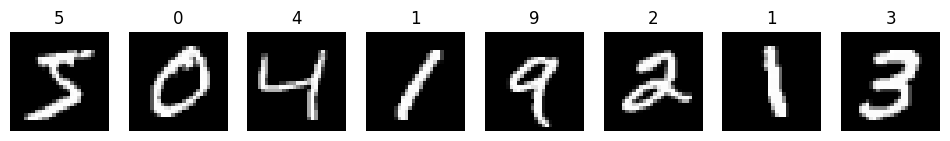

In [3]:
mnist_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_ds = datasets.MNIST("./data", train=True, download=True, transform=mnist_tf)
test_ds = datasets.MNIST("./data", train=False, download=True, transform=mnist_tf)

BATCH = 128
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
print(len(train_ds), "images d'entraînement,", len(test_ds), "images de test")

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, (img, lab) in zip(axes, [train_ds[i] for i in range(8)]):
    ax.imshow(img[0], cmap="gray"); ax.set_title(lab); ax.axis("off")
plt.show()

In [4]:
def evaluate(model, loader, criterion, prep=None):
    model.eval()
    total, ys, ps = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            if prep is not None:
                x = prep(x)
            out = model(x)
            total += criterion(out, y).item() * x.size(0)
            ps.append(out.argmax(1).cpu()); ys.append(y.cpu())
    ys = torch.cat(ys).numpy(); ps = torch.cat(ps).numpy()
    return total / len(ys), accuracy_score(ys, ps), f1_score(ys, ps, average="macro"), ys, ps


def fit(model, name, train_loader, test_loader, epochs, optimizer, scheduler=None, prep=None):
    criterion = nn.CrossEntropyLoss()
    model.to(device)
    hist = {"train_loss": [], "test_loss": [], "test_acc": [], "test_f1": []}
    train_time = 0.0
    for ep in range(1, epochs + 1):
        model.train()
        sync(); t0 = time.time()
        run, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            if prep is not None:
                x = prep(x)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            run += loss.item() * x.size(0); n += x.size(0)
        if scheduler is not None:
            scheduler.step()
        sync(); train_time += time.time() - t0
        vl, acc, f1, ys, ps = evaluate(model, test_loader, criterion, prep)
        hist["train_loss"].append(run / n); hist["test_loss"].append(vl)
        hist["test_acc"].append(acc); hist["test_f1"].append(f1)
        print(f"[{name}] epoch {ep:02d}/{epochs} | train loss {run/n:.4f} | test loss {vl:.4f} | acc {acc:.4f} | F1 {f1:.4f}")
    results[name] = {"Accuracy": acc, "F1 macro": f1, "Loss (test)": vl, "Temps (s)": train_time,
                     "Epochs": epochs, "Params (total)": count_params(model),
                     "Params (entraînés)": count_params(model, True)}
    histories[name] = hist
    predictions[name] = (ys, ps)
    return model

# Partie 1.1 – CNN from scratch
Architecture (entrée 1×28×28) :
- Conv1 : 32 filtres, kernel 3×3, stride 1, padding 1 + BatchNorm + ReLU → 32×28×28
- MaxPool 2×2 → 32×14×14
- Conv2 : 64 filtres, kernel 3×3, stride 1, padding 1 + BatchNorm + ReLU → 64×14×14
- MaxPool 2×2 → 64×7×7
- Dropout 0.25
- FC1 : 3136 → 128 + ReLU + Dropout 0.5
- FC2 : 128 → 10

Hyper-paramètres : Adam (lr = 1e-3), weight_decay = 1e-4 (régularisation L2), Dropout, batch 128, 5 époques, StepLR (γ = 0.5 toutes les 2 époques), loss CrossEntropy.

In [5]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.25),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn = SimpleCNN()
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=2, gamma=0.5)
cnn = fit(cnn, "CNN", train_loader, test_loader, epochs=5, optimizer=opt, scheduler=sched)

[CNN] epoch 01/5 | train loss 0.2425 | test loss 0.0571 | acc 0.9805 | F1 0.9804
[CNN] epoch 02/5 | train loss 0.1050 | test loss 0.0400 | acc 0.9878 | F1 0.9878
[CNN] epoch 03/5 | train loss 0.0736 | test loss 0.0338 | acc 0.9886 | F1 0.9885
[CNN] epoch 04/5 | train loss 0.0624 | test loss 0.0328 | acc 0.9891 | F1 0.9890
[CNN] epoch 05/5 | train loss 0.0523 | test loss 0.0255 | acc 0.9919 | F1 0.9918


# Partie 1.2 – Faster R-CNN
Faster R-CNN est un modèle de détection d'objets (boîtes englobantes + classes). Pour l'appliquer à MNIST :
- chaque chiffre 28×28 est placé à une position aléatoire sur un canevas noir 96×96 ;
- cible = boîte englobante du chiffre + classe (label + 1, la classe 0 = fond) ;
- à l'inférence, la classe de la détection au meilleur score sert de prédiction.

Modèle : fasterrcnn_mobilenet_v3_large_320_fpn (backbone pré-entraîné ImageNet), 11 classes.
Sous-ensemble : 8000 images train / 2000 test pour limiter le temps.
Attention : la loss de détection n'est pas directement comparable à la cross-entropy du CNN.

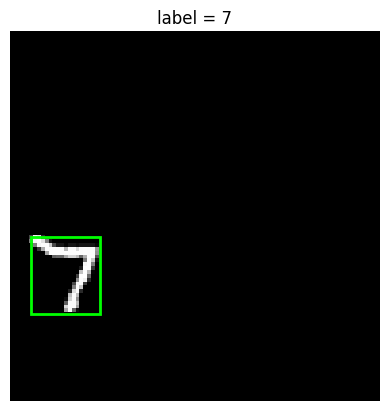

In [7]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn

DET_TRAIN_SIZE, DET_TEST_SIZE, DET_EPOCHS, DET_BATCH, CANVAS = 8000, 2000, 5, 32, 96

class MNISTDet(Dataset):
    def __init__(self, base, indices, canvas=CANVAS):
        self.base, self.indices, self.canvas = base, indices, canvas
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        idx = int(self.indices[i])
        img, label = self.base[idx]                      # img : (1,28,28) dans [0,1]
        rng = np.random.RandomState(idx)                 # position déterministe par image
        x0 = rng.randint(0, self.canvas - 28 + 1); y0 = rng.randint(0, self.canvas - 28 + 1)
        canvas = torch.zeros(1, self.canvas, self.canvas)
        canvas[:, y0:y0 + 28, x0:x0 + 28] = img
        ys, xs = torch.where(img[0] > 0.2)
        box = torch.tensor([[x0 + xs.min().item(), y0 + ys.min().item(),
                             x0 + xs.max().item() + 1, y0 + ys.max().item() + 1]], dtype=torch.float32)
        return canvas.repeat(3, 1, 1), {"boxes": box, "labels": torch.tensor([label + 1])}

def collate(batch):
    return tuple(zip(*batch))

det_train_base = datasets.MNIST("./data", train=True, download=True, transform=transforms.ToTensor())
det_test_base = datasets.MNIST("./data", train=False, download=True, transform=transforms.ToTensor())
rs = np.random.RandomState(SEED)
tr_idx = rs.choice(len(det_train_base), DET_TRAIN_SIZE, replace=False)
te_idx = rs.choice(len(det_test_base), DET_TEST_SIZE, replace=False)
det_train_loader = DataLoader(MNISTDet(det_train_base, tr_idx), batch_size=DET_BATCH, shuffle=True, collate_fn=collate, num_workers=2)
det_test_loader = DataLoader(MNISTDet(det_test_base, te_idx), batch_size=DET_BATCH, shuffle=False, collate_fn=collate, num_workers=2)

# Aperçu d'un exemple avec sa boîte
im, tg = MNISTDet(det_train_base, tr_idx)[0]
b = tg["boxes"][0]
plt.imshow(im[0], cmap="gray")
plt.gca().add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, edgecolor="lime", lw=2))
plt.title(f"label = {tg['labels'].item() - 1}"); plt.axis("off"); plt.show()

def build_faster_rcnn(num_classes=11):
    model = fasterrcnn_mobilenet_v3_large_320_fpn(weights=None,
        weights_backbone=models.MobileNet_V3_Large_Weights.IMAGENET1K_V1, num_classes=num_classes,
        min_size=320, max_size=320)
    return model

In [8]:
def bn_eval(model):
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            m.eval()

@torch.no_grad()
def eval_det(model, loader):
    total_loss, n, ys, ps = 0.0, 0, [], []
    for imgs, targets in loader:
        imgs = [i.to(device) for i in imgs]
        tg = [{k: v.to(device) for k, v in t.items()} for t in targets]
        model.train(); bn_eval(model)                    # mode train pour obtenir les losses (BN figée)
        total_loss += sum(model(imgs, tg).values()).item() * len(imgs)
        model.eval()                                     # mode eval pour obtenir les prédictions
        outs = model(imgs)
        for o, t in zip(outs, targets):
            ys.append(t["labels"].item() - 1)
            ps.append(o["labels"][o["scores"].argmax()].item() - 1 if len(o["scores"]) > 0 else -1)
        n += len(imgs)
    ys, ps = np.array(ys), np.array(ps)
    return total_loss / n, accuracy_score(ys, ps), f1_score(ys, ps, average="macro", labels=list(range(10))), ys, ps

det_model = build_faster_rcnn().to(device)
params = [p for p in det_model.parameters() if p.requires_grad]
det_opt = torch.optim.SGD(params, lr=0.01, momentum=0.9, weight_decay=1e-4)
det_sched = torch.optim.lr_scheduler.StepLR(det_opt, step_size=3, gamma=0.1)

hist = {"train_loss": [], "test_loss": [], "test_acc": [], "test_f1": []}
det_time = 0.0
for ep in range(1, DET_EPOCHS + 1):
    det_model.train()
    sync(); t0 = time.time()
    run, n = 0.0, 0
    for imgs, targets in det_train_loader:
        imgs = [i.to(device) for i in imgs]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss = sum(det_model(imgs, targets).values())
        det_opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(params, 10.0)
        det_opt.step()
        run += loss.item() * len(imgs); n += len(imgs)
    det_sched.step()
    sync(); det_time += time.time() - t0
    vl, acc, f1, ys, ps = eval_det(det_model, det_test_loader)
    hist["train_loss"].append(run / n); hist["test_loss"].append(vl)
    hist["test_acc"].append(acc); hist["test_f1"].append(f1)
    print(f"[Faster R-CNN] epoch {ep:02d}/{DET_EPOCHS} | train loss {run/n:.4f} | test loss {vl:.4f} | acc {acc:.4f} | F1 {f1:.4f}")

results["Faster R-CNN"] = {"Accuracy": acc, "F1 macro": f1, "Loss (test)": vl, "Temps (s)": det_time,
                           "Epochs": DET_EPOCHS, "Params (total)": count_params(det_model),
                           "Params (entraînés)": count_params(det_model, True)}
histories["Faster R-CNN"] = hist
predictions["Faster R-CNN"] = (ys, ps)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 162MB/s]


[Faster R-CNN] epoch 01/5 | train loss 0.6910 | test loss 0.8066 | acc 0.7100 | F1 0.6609
[Faster R-CNN] epoch 02/5 | train loss 0.5458 | test loss 0.4404 | acc 0.9675 | F1 0.9670
[Faster R-CNN] epoch 03/5 | train loss 0.4267 | test loss 0.4149 | acc 0.9605 | F1 0.9602
[Faster R-CNN] epoch 04/5 | train loss 0.2734 | test loss 0.2949 | acc 0.9870 | F1 0.9867
[Faster R-CNN] epoch 05/5 | train loss 0.2741 | test loss 0.3012 | acc 0.9865 | F1 0.9862


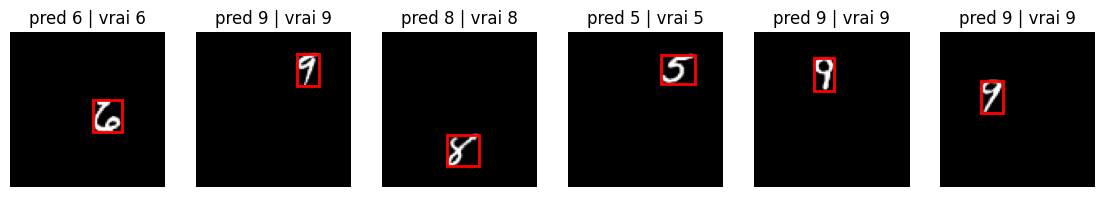

In [9]:
det_model.eval()
fig, axes = plt.subplots(1, 6, figsize=(14, 3))
ds_vis = MNISTDet(det_test_base, te_idx)
for ax, i in zip(axes, range(6)):
    im, tg = ds_vis[i]
    with torch.no_grad():
        o = det_model([im.to(device)])[0]
    ax.imshow(im[0], cmap="gray"); ax.axis("off")
    if len(o["scores"]) > 0:
        k = o["scores"].argmax(); bx = o["boxes"][k].cpu()
        ax.add_patch(plt.Rectangle((bx[0], bx[1]), bx[2] - bx[0], bx[3] - bx[1], fill=False, edgecolor="red", lw=2))
        ax.set_title(f"pred {o['labels'][k].item()-1} | vrai {tg['labels'].item()-1}")
    else:
        ax.set_title(f"aucune détection | vrai {tg['labels'].item()-1}")
plt.show()

# Partie 1.3 – Comparaison CNN vs Faster R-CNN

,Accuracy,F1 macro,Loss (test),Temps (s),Epochs,Params (total),Params (entraînés)
CNN,0.9919,0.9918,0.0255,44.5,5,"421,834","421,834"
Faster R-CNN,0.9865,0.9862,0.3012,406.7,5,"18,976,354","18,917,458"


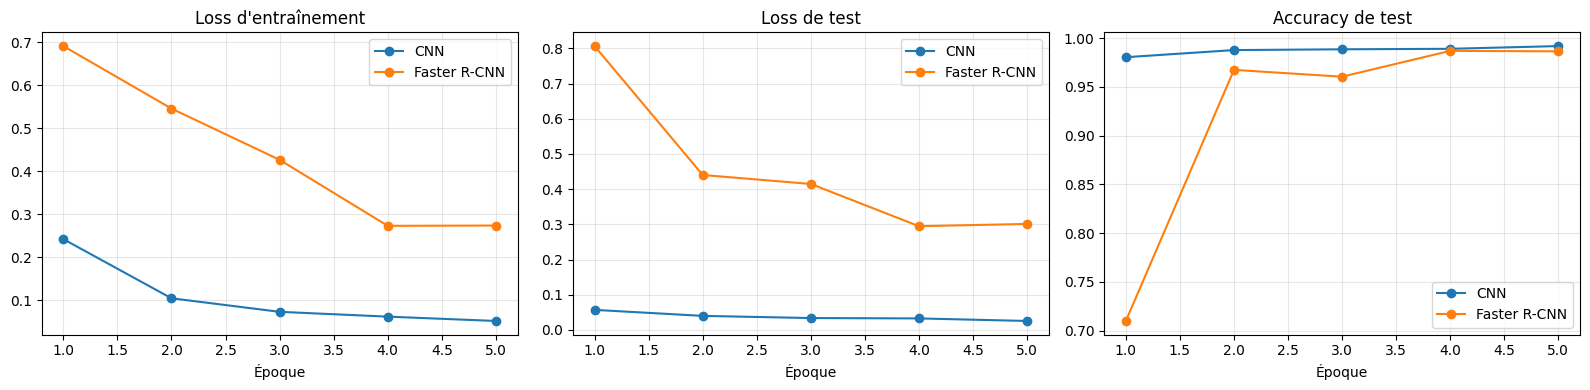

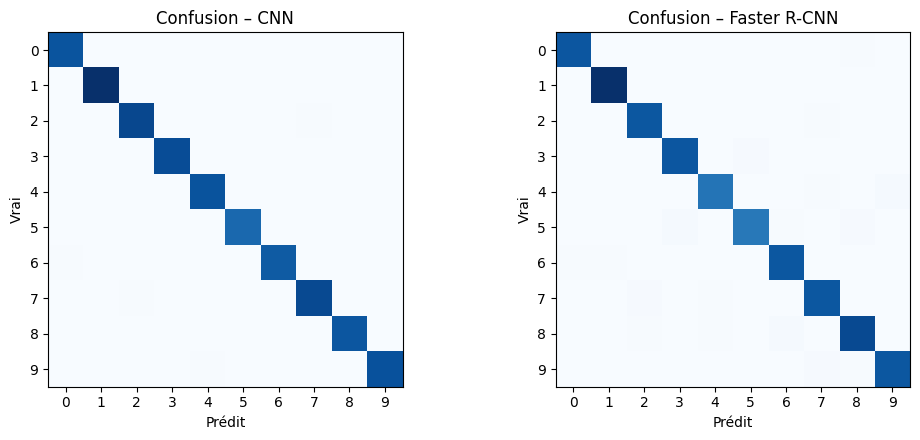

In [10]:
def show_table(names=None):
    df = pd.DataFrame(results).T
    if names: df = df.loc[names]
    fmt = {"Accuracy": "{:.4f}", "F1 macro": "{:.4f}", "Loss (test)": "{:.4f}", "Temps (s)": "{:.1f}",
           "Params (total)": "{:,.0f}", "Params (entraînés)": "{:,.0f}", "Epochs": "{:.0f}"}
    display(df.style.format(fmt))
    return df

def plot_curves(names):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for n in names:
        h = histories[n]; ep = range(1, len(h["test_acc"]) + 1)
        axes[0].plot(ep, h["train_loss"], marker="o", label=n)
        axes[1].plot(ep, h["test_loss"], marker="o", label=n)
        axes[2].plot(ep, h["test_acc"], marker="o", label=n)
    for ax, t in zip(axes, ["Loss d'entraînement", "Loss de test", "Accuracy de test"]):
        ax.set_title(t); ax.set_xlabel("Époque"); ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.show()

def plot_confusions(names):
    fig, axes = plt.subplots(1, len(names), figsize=(5.2 * len(names), 4.5), squeeze=False)
    for ax, n in zip(axes[0], names):
        ys, ps = predictions[n]
        ax.imshow(confusion_matrix(ys, ps, labels=list(range(10))), cmap="Blues")
        ax.set_title(f"Confusion – {n}"); ax.set_xlabel("Prédit"); ax.set_ylabel("Vrai")
        ax.set_xticks(range(10)); ax.set_yticks(range(10))
    plt.tight_layout(); plt.show()

_ = show_table(["CNN", "Faster R-CNN"])
plot_curves(["CNN", "Faster R-CNN"])
plot_confusions(["CNN", "Faster R-CNN"])

### Analyse : CNN vs Faster R-CNN

| | CNN | Faster R-CNN |
|---|---|---|
| Accuracy | 99,19 % | 98,65 % |
| F1 macro | 0,9918 | 0,9862 |
| Loss test | 0,0255 | 0,3012 |
| Temps d'entraînement | 44,5 s | 406,7 s |
| Paramètres | 0,42 M | 18,98 M |

- **Précision** : le CNN reste meilleur, avec +0,54 point d'accuracy et +0,56 point de F1, mais l'écart est faible. Le CNN atteint déjà 98,05 % dès la 1re époque. Faster R-CNN démarre à 71,0 %, monte à 96,75 % à l'époque 2, fluctue à l'époque 3 (96,05 %), puis se stabilise autour de 98,7 % aux époques 4 et 5.
- **Loss** : les deux valeurs ne sont pas comparables. Le CNN utilise une cross-entropy, alors que Faster R-CNN additionne plusieurs losses (RPN, classification, régression des boîtes). On compare seulement leur tendance : les deux décroissent.
- **Temps et taille** : Faster R-CNN est environ 9 fois plus lent (≈ 6,8 min contre 44,5 s) et possède environ 45 fois plus de paramètres.
- **Qualitatif** : les boîtes prédites sont bien centrées sur les chiffres et les classes sont correctes sur les exemples affichés. Les matrices de confusion sont quasi diagonales, avec un peu plus d'erreurs diffuses pour Faster R-CNN (classes 4 et 5).
- **Limites** : Faster R-CNN est entraîné sur 8 000 images et évalué sur 2 000 images, alors que le CNN utilise 60 000 / 10 000 images. De plus, l'entraînement n'est pas totalement reproductible : un run précédent avait donné 96,05 % pour Faster R-CNN. Des écarts de quelques dixièmes de point ne sont donc pas significatifs.
- **Conclusion** : Faster R-CNN est conçu pour localiser et classer des objets dans une scène. Pour classer des chiffres, le CNN est un peu plus précis, environ 9 fois plus rapide et beaucoup plus léger. Faster R-CNN n'est utile que si la position des objets varie ou s'il y en a plusieurs par image.

# Partie 1.4 – Fine-tuning de VGG16 et AlexNet
- Poids pré-entraînés ImageNet.
- MNIST redimensionné en 64×64 et répété sur 3 canaux (fait sur GPU).
- Couches convolutives gelées ; dernière couche remplacée (1000 → 10) ; on entraîne les couches FC.
- Sous-ensemble de 20 000 images d'entraînement (VGG16 est lourd) ; test sur tout le test set.

In [11]:
def prep_tl(x):
    return F.interpolate(x.repeat(1, 3, 1, 1), size=(64, 64), mode="bilinear", align_corners=False)

TL_TRAIN_SIZE, TL_EPOCHS = 20000, 3
tl_idx = np.random.RandomState(SEED).choice(len(train_ds), TL_TRAIN_SIZE, replace=False)
tl_loader = DataLoader(Subset(train_ds, tl_idx), batch_size=64, shuffle=True, num_workers=2, pin_memory=True)

def build_vgg16():
    m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
    for p in m.features.parameters():
        p.requires_grad = False
    m.classifier[6] = nn.Linear(4096, 10)
    return m

def build_alexnet():
    m = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
    for p in m.features.parameters():
        p.requires_grad = False
    m.classifier[6] = nn.Linear(4096, 10)
    return m

for name, builder in [("AlexNet (fine-tuned)", build_alexnet), ("VGG16 (fine-tuned)", build_vgg16)]:
    m = builder()
    opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=1e-4, weight_decay=1e-4)
    fit(m, name, tl_loader, test_loader, epochs=TL_EPOCHS, optimizer=opt, prep=prep_tl)
    del m
    if device.type == "cuda":
        torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 220MB/s] 


[AlexNet (fine-tuned)] epoch 01/3 | train loss 0.4423 | test loss 0.2052 | acc 0.9302 | F1 0.9291
[AlexNet (fine-tuned)] epoch 02/3 | train loss 0.2497 | test loss 0.1791 | acc 0.9391 | F1 0.9380
[AlexNet (fine-tuned)] epoch 03/3 | train loss 0.2119 | test loss 0.1746 | acc 0.9402 | F1 0.9391
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 186MB/s] 


[VGG16 (fine-tuned)] epoch 01/3 | train loss 0.3742 | test loss 0.1830 | acc 0.9416 | F1 0.9409
[VGG16 (fine-tuned)] epoch 02/3 | train loss 0.1579 | test loss 0.1249 | acc 0.9602 | F1 0.9601
[VGG16 (fine-tuned)] epoch 03/3 | train loss 0.1255 | test loss 0.1180 | acc 0.9615 | F1 0.9612


,Accuracy,F1 macro,Loss (test),Temps (s),Epochs,Params (total),Params (entraînés)
CNN,0.9919,0.9918,0.0255,44.5,5,"421,834","421,834"
Faster R-CNN,0.9865,0.9862,0.3012,406.7,5,"18,976,354","18,917,458"
AlexNet (fine-tuned),0.9402,0.9391,0.1746,25.7,3,"57,044,810","54,575,114"
VGG16 (fine-tuned),0.9615,0.9612,0.1180,71.6,3,"134,301,514","119,586,826"


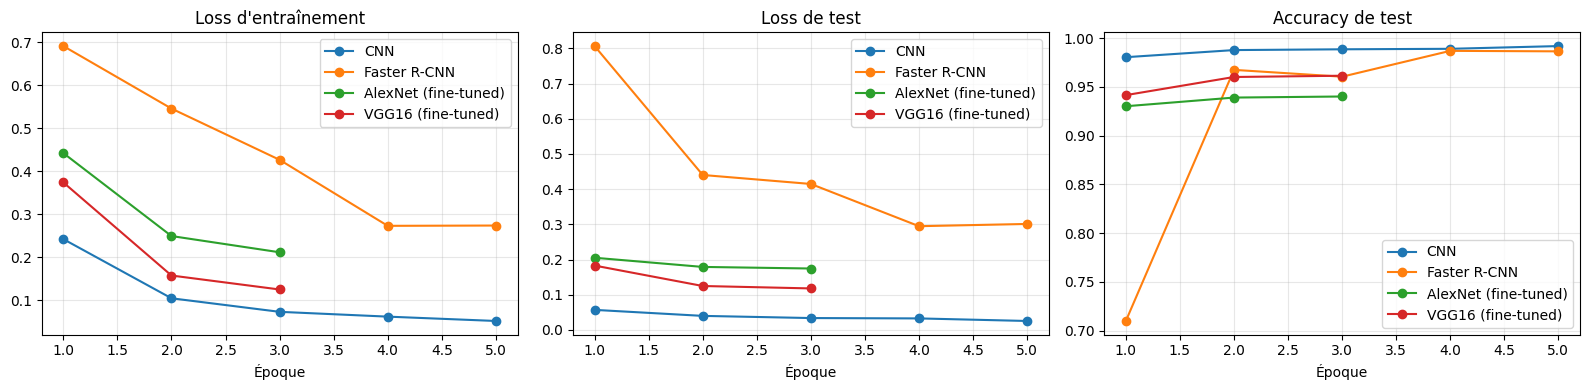

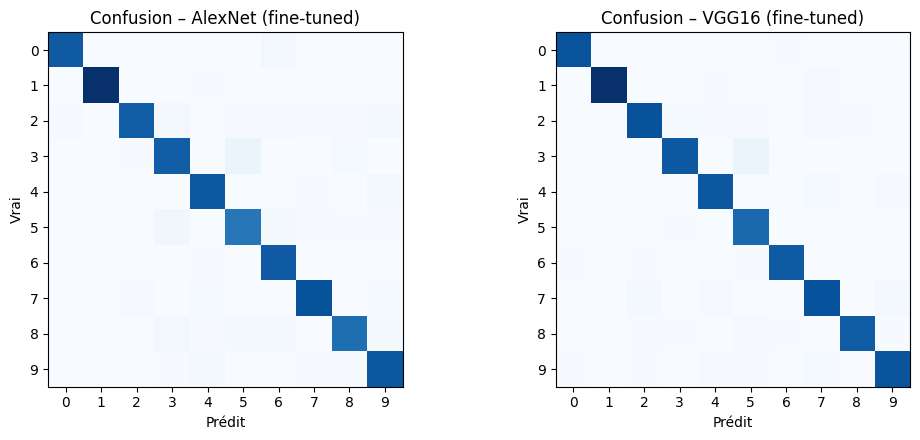

In [12]:
all_p1 = ["CNN", "Faster R-CNN", "AlexNet (fine-tuned)", "VGG16 (fine-tuned)"]
_ = show_table(all_p1)
plot_curves(all_p1)
plot_confusions(["AlexNet (fine-tuned)", "VGG16 (fine-tuned)"])

### Conclusion de la partie 1

**Classement par accuracy** : CNN (99,19 %) > Faster R-CNN (98,65 %) > VGG16 fine-tuned (96,15 %) > AlexNet fine-tuned (94,02 %).

- **VGG16 vs AlexNet** : VGG16 gagne environ 2,1 points (96,15 % contre 94,02 %) et a une meilleure loss (0,1180 contre 0,1746), mais il est 2,8 fois plus lent (71,6 s contre 25,7 s) et 2,4 fois plus lourd (134 M de paramètres contre 57 M). AlexNet plafonne (93,0 → 93,9 → 94,0 %), alors que la loss de test de VGG16 continue de baisser sur les 3 époques, sans surapprentissage net.
- **Pourquoi le fine-tuning ne bat pas le CNN** :
  - ImageNet est composé d'images naturelles en couleur, alors que MNIST contient des chiffres en niveaux de gris.
  - Les images 28×28 sont agrandies en 64×64 et leur canal est répété 3 fois.
  - Les couches convolutives sont gelées, donc non adaptées à MNIST.
  - L'entraînement porte sur 20 000 images et 3 époques seulement.
  - Le CNN, lui, est spécialisé et entraîné sur les 60 000 images.
- **Faster R-CNN vs modèles fine-tunés** : Faster R-CNN est plus précis (98,65 % contre 96,15 % pour VGG16) mais environ 5,7 fois plus lent que VGG16.
- **Coût** : VGG16 et AlexNet ont respectivement ≈ 320 et ≈ 135 fois plus de paramètres que le CNN (0,42 M), pour une précision inférieure. Le transfer learning est surtout utile quand les données sont peu nombreuses ou complexes, ce qui n'est pas le cas de MNIST.
- **Conclusion** : sur MNIST, le CNN conçu pour la tâche est le meilleur compromis précision / temps / taille. Une piste d'amélioration serait de dégeler les derniers blocs convolutifs des modèles pré-entraînés.

# Partie 2 – Vision Transformer (ViT) from scratch
1. Patchify : image 28×28 → 49 patchs de 4×4 (vecteurs de dimension 16).
2. Projection linéaire vers la dimension cachée d.
3. Ajout d'un class token + encodage positionnel sinusoïdal.
4. Blocs Transformer : LayerNorm → Multi-Head Self-Attention (+ résiduel) → LayerNorm → MLP (+ résiduel).
5. Tête de classification sur le class token.

Hyper-paramètres : d = 64, 4 têtes, 4 blocs, MLP ratio 4, patch 4×4, AdamW (lr 1e-3, weight_decay 1e-2), scheduler cosinus, 10 époques.

In [13]:
def get_positional_embeddings(n_tokens, d):
    pe = torch.ones(n_tokens, d)
    for i in range(n_tokens):
        for j in range(d):
            pe[i, j] = np.sin(i / 10000 ** (j / d)) if j % 2 == 0 else np.cos(i / 10000 ** ((j - 1) / d))
    return pe

def patchify(images, patch_size):
    # (B, C, H, W) -> (B, n_patches, C*patch*patch)
    B, C, H, W = images.shape
    p = images.unfold(2, patch_size, patch_size).unfold(3, patch_size, patch_size)   # B,C,H/p,W/p,p,p
    return p.permute(0, 2, 3, 1, 4, 5).reshape(B, (H // patch_size) * (W // patch_size), C * patch_size * patch_size)

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        assert d % n_heads == 0
        self.h, self.dh = n_heads, d // n_heads
        self.qkv = nn.Linear(d, 3 * d)
        self.proj = nn.Linear(d, d)

    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, self.dh).permute(2, 0, 3, 1, 4)
        att = torch.softmax(q @ k.transpose(-2, -1) / self.dh ** 0.5, dim=-1)
        out = (att @ v).transpose(1, 2).reshape(B, N, D)
        return self.proj(out)

class ViTBlock(nn.Module):
    def __init__(self, d, n_heads, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(d)
        self.mhsa = MultiHeadSelfAttention(d, n_heads)
        self.norm2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, mlp_ratio * d), nn.GELU(), nn.Linear(mlp_ratio * d, d))

    def forward(self, x):
        x = x + self.mhsa(self.norm1(x))
        return x + self.mlp(self.norm2(x))

class ViT(nn.Module):
    def __init__(self, in_shape=(1, 28, 28), patch_size=4, d=64, n_heads=4, n_blocks=4, n_classes=10):
        super().__init__()
        C, H, W = in_shape
        assert H % patch_size == 0 and W % patch_size == 0
        self.patch_size = patch_size
        n_patches = (H // patch_size) * (W // patch_size)
        self.linear_mapper = nn.Linear(C * patch_size * patch_size, d)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        self.register_buffer("pos_embed", get_positional_embeddings(n_patches + 1, d), persistent=False)
        self.blocks = nn.Sequential(*[ViTBlock(d, n_heads) for _ in range(n_blocks)])
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, n_classes)

    def forward(self, x):
        tokens = self.linear_mapper(patchify(x, self.patch_size))
        tokens = torch.cat([self.cls_token.expand(x.size(0), -1, -1), tokens], dim=1) + self.pos_embed
        tokens = self.norm(self.blocks(tokens))
        return self.head(tokens[:, 0])

vit = ViT()
print("Paramètres ViT :", f"{count_params(vit):,}")
print("Test forward :", vit(torch.randn(2, 1, 28, 28)).shape)

Paramètres ViT : 201,866
Test forward : torch.Size([2, 10])


In [14]:
VIT_EPOCHS = 10
vit = ViT()
vit_opt = torch.optim.AdamW(vit.parameters(), lr=1e-3, weight_decay=1e-2)
vit_sched = torch.optim.lr_scheduler.CosineAnnealingLR(vit_opt, T_max=VIT_EPOCHS)
vit = fit(vit, "ViT", train_loader, test_loader, epochs=VIT_EPOCHS, optimizer=vit_opt, scheduler=vit_sched)

[ViT] epoch 01/10 | train loss 0.6741 | test loss 0.1737 | acc 0.9483 | F1 0.9477
[ViT] epoch 02/10 | train loss 0.1563 | test loss 0.1117 | acc 0.9659 | F1 0.9656
[ViT] epoch 03/10 | train loss 0.1032 | test loss 0.0882 | acc 0.9722 | F1 0.9720
[ViT] epoch 04/10 | train loss 0.0771 | test loss 0.0736 | acc 0.9759 | F1 0.9757
[ViT] epoch 05/10 | train loss 0.0573 | test loss 0.0767 | acc 0.9758 | F1 0.9756
[ViT] epoch 06/10 | train loss 0.0426 | test loss 0.0652 | acc 0.9803 | F1 0.9801
[ViT] epoch 07/10 | train loss 0.0283 | test loss 0.0581 | acc 0.9838 | F1 0.9836
[ViT] epoch 08/10 | train loss 0.0183 | test loss 0.0531 | acc 0.9839 | F1 0.9837
[ViT] epoch 09/10 | train loss 0.0113 | test loss 0.0545 | acc 0.9844 | F1 0.9842
[ViT] epoch 10/10 | train loss 0.0080 | test loss 0.0516 | acc 0.9851 | F1 0.9849


## Partie 2.2 – Interprétation et comparaison avec la partie 1

,Accuracy,F1 macro,Loss (test),Temps (s),Epochs,Params (total),Params (entraînés)
CNN,0.9919,0.9918,0.0255,44.5,5,"421,834","421,834"
Faster R-CNN,0.9865,0.9862,0.3012,406.7,5,"18,976,354","18,917,458"
AlexNet (fine-tuned),0.9402,0.9391,0.1746,25.7,3,"57,044,810","54,575,114"
VGG16 (fine-tuned),0.9615,0.9612,0.1180,71.6,3,"134,301,514","119,586,826"
ViT,0.9851,0.9849,0.0516,89.1,10,"201,866","201,866"


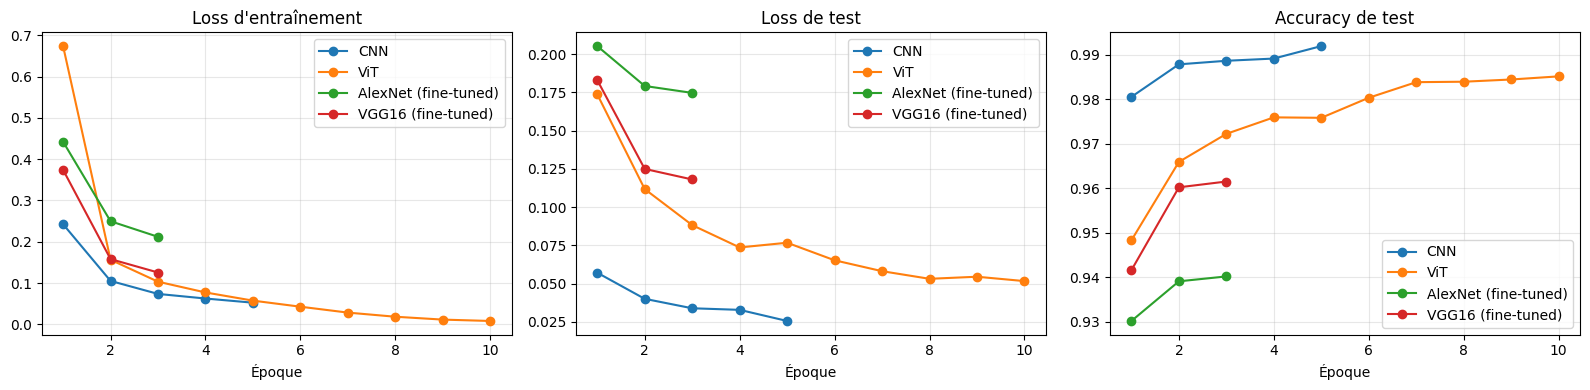

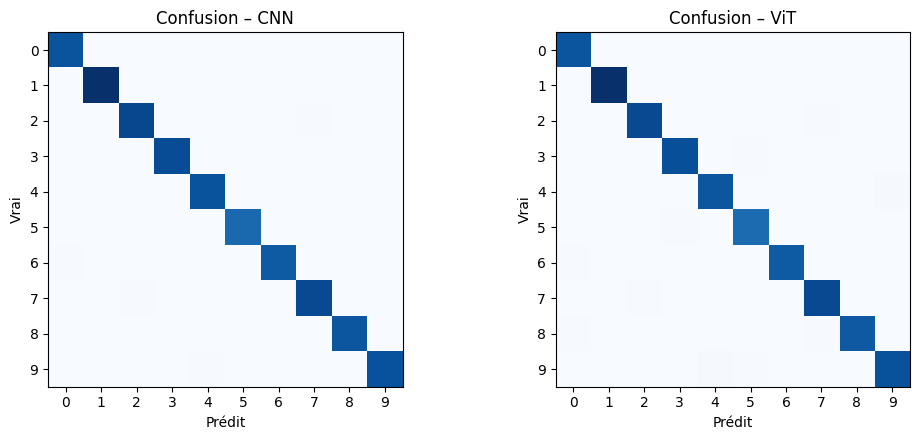

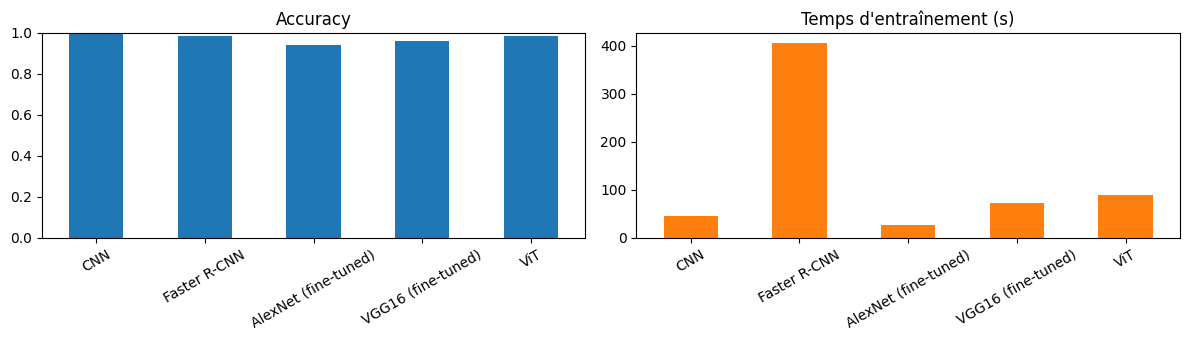

In [15]:
all_models = ["CNN", "Faster R-CNN", "AlexNet (fine-tuned)", "VGG16 (fine-tuned)", "ViT"]
df_final = show_table(all_models)
plot_curves(["CNN", "ViT", "AlexNet (fine-tuned)", "VGG16 (fine-tuned)"])
plot_confusions(["CNN", "ViT"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
df_final["Accuracy"].plot.bar(ax=axes[0], title="Accuracy", rot=30, color="tab:blue", ylim=(0, 1.0))
df_final["Temps (s)"].plot.bar(ax=axes[1], title="Temps d'entraînement (s)", rot=30, color="tab:orange")
plt.tight_layout(); plt.show()

df_final.to_csv("results.csv")

### Interprétation du ViT et comparaison avec la partie 1

| Modèle | Accuracy | F1 | Loss test | Temps (s) | Paramètres |
|---|---|---|---|---|---|
| CNN | 0,9919 | 0,9918 | 0,0255 | 44,5 | 421 834 |
| Faster R-CNN | 0,9865 | 0,9862 | 0,3012 | 406,7 | 18 976 354 |
| ViT | 0,9851 | 0,9849 | 0,0516 | 89,1 | 201 866 |
| VGG16 (FT) | 0,9615 | 0,9612 | 0,1180 | 71,6 | 134 301 514 |
| AlexNet (FT) | 0,9402 | 0,9391 | 0,1746 | 25,7 | 57 044 810 |

- **Performance** : le ViT entraîné from scratch atteint 98,51 %, ce qui le place 3e, derrière le CNN (écart de 0,68 point) et Faster R-CNN (écart de 0,14 point, négligeable vu la variabilité des runs). Il dépasse nettement VGG16 et AlexNet fine-tunés, sans aucun pré-entraînement.
- **Efficacité** : avec 0,20 M de paramètres, c'est le plus petit modèle (la moitié du CNN). Face à Faster R-CNN, il a environ 94 fois moins de paramètres et s'entraîne environ 4,6 fois plus vite pour une précision quasi identique.
- **Convergence** : le ViT démarre plus lentement (94,8 % à l'époque 1 contre 98,05 % pour le CNN) et a besoin de 10 époques. Son accuracy se stabilise autour de 98,4 – 98,5 % à partir de l'époque 8.
- **Surapprentissage** : l'écart entre la loss d'entraînement (0,0080) et celle de test (0,0516) montre une généralisation moins bonne que celle du CNN. De la data augmentation ou davantage de régularisation pourraient aider.
- **Biais inductif** : le CNN intègre la localité et l'invariance par translation grâce aux convolutions et au pooling, ce qui convient très bien à MNIST. Le ViT doit apprendre ces propriétés via l'attention entre patchs, d'où une convergence plus lente et un besoin de plus de données.
- **Coût** : le temps par époque est quasi identique (≈ 8,9 s pour les deux), mais le ViT a besoin de 2 fois plus d'époques, donc ≈ 2 fois plus de temps total.
- **Matrices de confusion** : celles du CNN et du ViT sont quasi diagonales, avec très peu d'erreurs.
- **Conclusion** : sur un dataset simple comme MNIST, un petit CNN reste le meilleur choix. Le ViT est très compétitif sans pré-entraînement, et ses avantages apparaissent sur de grands datasets ou avec du pré-entraînement.
- **Limites** : les modèles n'ont pas le même nombre d'époques (5, 3 ou 10) ni les mêmes sous-ensembles de données, et les résultats varient légèrement d'un run à l'autre. La comparaison reste donc indicative.

# Synthèse personnelle
Ce que j'ai appris pendant ce TP :
- Prise en main de PyTorch : Dataset/DataLoader, nn.Module, boucle d'entraînement, GPU (.to(device)).
- Construction d'un CNN et rôle des hyper-paramètres (kernel, padding, stride, pooling, optimiseur, Dropout, weight decay, BatchNorm).
- Différence entre classification et détection d'objets (Faster R-CNN : RPN, RoI heads, boîtes englobantes).
- Transfer learning : geler les features, remplacer la tête, fine-tuning de VGG16 / AlexNet.
- Fonctionnement d'un Vision Transformer : patchs, class token, encodage positionnel, self-attention.
- Comparaison de modèles avec Accuracy, F1-score, loss, temps et nombre de paramètres.